In [229]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import mip

BUILDING_NAME = "Edificio1.csv"

ASCENDING_SPEED = 1.0
DESCENDING_SPEED = 2.0
HORIZONTAL_SPEED = 1.5

ASCENDING_ENERGY = 50
DESCENDING_ENERGY = 5
HORIZONTAL_ENERGY = 10

X_BASE_RANGE = range(-8, 6) if "Edificio1.csv" == BUILDING_NAME else range(-10, 11)
Y_BASE_RANGE = range(-17, -14) if "Edificio1.csv" == BUILDING_NAME else range(-31, -29)
Z_BASE = 0

BATTERY_CAPACITY = 3600 if "Edificio1.csv" == BUILDING_NAME else 21600  # 1 Wh is 3600 J

Y_ENTRY_POINT = -12.5 if "Edificio1.csv" == BUILDING_NAME else -20.0

# Reading CSV and creating pairs


In [230]:
# loading building csv data

nodes = pd.read_csv("test.csv")

# Creating Bases and entry points

In [231]:
# Adding is_base and is_entry_point columns

nodes["is_base"] = False

nodes["is_entry_point"] = nodes["y"] <= Y_ENTRY_POINT


# Creating new rows for base points
bases = []
bases.append({"x": 0, "y": -15, "z": Z_BASE, "is_base": True, "is_entry_point": False})
#bases.append({"x": -8, "y": -17, "z": Z_BASE, "is_base": True, "is_entry_point": False})
#bases.append({"x": 5, "y": -14, "z": Z_BASE, "is_base": True, "is_entry_point": False})

# Appending base rows to the building dataframe
building = pd.concat([nodes, pd.DataFrame(bases)], ignore_index=True)

building.to_csv("building.csv", index=False)

# Merging nodes to create pairs

In [232]:
# setting node numbering from 1 to n
building.index += 1

# generating all possible pairs of points (edges)
nodes_pairs = (
    building.rename_axis("source_node")
    .reset_index()
    .merge(building.rename_axis("target_node").reset_index(), how="cross")
)

# removing self-self pairs
nodes_pairs = nodes_pairs[
    nodes_pairs["source_node"] != nodes_pairs["target_node"]
]  # keeping only pairs with different points

In [233]:
first_point_cols = ["x_x", "y_x", "z_x"]
second_point_cols = ["x_y", "y_y", "z_y"]
diff_cols = ["dx", "dy", "dz"]

# Computing distances 

In [234]:
# function to determine if two points are connected based on distance and coordinate deltas


def process_connections(dataframe):
    # distances and deltas on coordinates
    dataframe[diff_cols] = (
        dataframe[second_point_cols].values - dataframe[first_point_cols].values
    )
    dataframe["euclidean_distance"] = np.sqrt(
        (dataframe[diff_cols] ** 2).sum(axis=1)
    )  # axis=1 sum on columns

    # conditions near and tunnel
    condition_near = dataframe["euclidean_distance"] <= 4.0

    condition_tunnel = (
        ((dataframe["dx"].abs() <= 0.5) & (dataframe["dy"].abs() <= 0.5))
        | ((dataframe["dy"].abs() <= 0.5) & (dataframe["dz"].abs() <= 0.5))
        | ((dataframe["dx"].abs() <= 0.5) & (dataframe["dz"].abs() <= 0.5))
    )

    condition_tunnel_and_not_far = (
        dataframe["euclidean_distance"] <= 11.0
    ) & condition_tunnel

    # if the arc is from base to entry point or viceversa
    condition_base_to_entry_point = (
        (dataframe["is_base_x"]) & (dataframe["is_entry_point_y"])
    ) | ((dataframe["is_base_y"]) & (dataframe["is_entry_point_x"]))

    # if both points are base points
    condition_base_to_base = (dataframe["is_base_x"]) & (dataframe["is_base_y"])

    # final connection condition
    dataframe["are_connected"] = (
        (condition_near & ~condition_base_to_base)
        | (condition_tunnel_and_not_far & ~condition_base_to_base)
        | condition_base_to_entry_point
    )
    return dataframe

In [235]:
nodes_pairs = process_connections(nodes_pairs)

nodes_pairs.to_csv("pairs.csv", index=False)

nodes_pairs.head()

,source_node,x_x,y_x,z_x,is_base_x,is_entry_point_x,target_node,x_y,y_y,z_y,is_base_y,is_entry_point_y,dx,dy,dz,euclidean_distance,are_connected
1,1,0.0,-14.0,0.0,False,True,2,3.0,-14.0,0.0,False,True,3.0,0.0,0.0,3.0,True
2,1,0.0,-14.0,0.0,False,True,3,-3.0,-14.0,0.0,False,True,-3.0,0.0,0.0,3.0,True
3,1,0.0,-14.0,0.0,False,True,4,0.0,-12.5,0.0,False,True,0.0,1.5,0.0,1.5,True
4,1,0.0,-14.0,0.0,False,True,5,2.0,-13.0,2.0,False,True,2.0,1.0,2.0,3.0,True
5,1,0.0,-14.0,0.0,False,True,6,0.0,-10.0,0.0,False,False,0.0,4.0,0.0,4.0,True


In [236]:
# computing vertical distances on z and distances on horizontal plane x,y
nodes_pairs["d_horizontal"] = np.sqrt(nodes_pairs["dx"] ** 2 + nodes_pairs["dy"] ** 2)
nodes_pairs["d_vertical"] = nodes_pairs["dz"]

# dropping columns that are not useful anymore
nodes_pairs.drop(columns=["dx", "dy", "dz"], inplace=True)
nodes_pairs.drop(columns=["x_x", "y_x", "z_x", "x_y", "y_y", "z_y"], inplace=True)

# keeping only connected pairs
nodes_pairs = nodes_pairs[nodes_pairs["are_connected"] == True]
nodes_pairs.drop(columns=["are_connected"], inplace=True)

nodes_pairs.head(5)

,source_node,is_base_x,is_entry_point_x,target_node,is_base_y,is_entry_point_y,euclidean_distance,d_horizontal,d_vertical
1,1,False,True,2,False,True,3.0,3.000000,0.0
2,1,False,True,3,False,True,3.0,3.000000,0.0
3,1,False,True,4,False,True,1.5,1.500000,0.0
4,1,False,True,5,False,True,3.0,2.236068,2.0
5,1,False,True,6,False,False,4.0,4.000000,0.0


# Function for time travel

In [237]:
# finding rows corresponding to different movement types

d_horizontal = nodes_pairs["d_horizontal"]
d_vertical = nodes_pairs["d_vertical"]
rows_horizontal = d_vertical == 0
rows_ascending = (d_horizontal == 0) & (d_vertical > 0)
rows_descending = (d_horizontal == 0) & (d_vertical < 0)
rows_oblique_ascending = (d_horizontal != 0) & (d_vertical > 0)
rows_oblique_descending = (d_horizontal != 0) & (d_vertical < 0)

In [238]:
# function for time travel based on movement types and speeds


def compute_time_travel(dataframe):
    dataframe.loc[rows_horizontal, "time_travel"] = (
        dataframe.loc[rows_horizontal, "d_horizontal"] / HORIZONTAL_SPEED
    )

    dataframe.loc[rows_ascending, "time_travel"] = (
        dataframe.loc[rows_ascending, "d_vertical"] / ASCENDING_SPEED
    )
    dataframe.loc[rows_descending, "time_travel"] = (
        -dataframe.loc[rows_descending, "d_vertical"] / DESCENDING_SPEED
    )

    dataframe.loc[rows_oblique_ascending, "time_travel"] = np.maximum(
        dataframe.loc[rows_oblique_ascending, "d_horizontal"] / HORIZONTAL_SPEED,
        dataframe.loc[rows_oblique_ascending, "d_vertical"] / ASCENDING_SPEED,
    )

    dataframe.loc[rows_oblique_descending, "time_travel"] = np.maximum(
        dataframe.loc[rows_oblique_descending, "d_horizontal"] / HORIZONTAL_SPEED,
        -dataframe.loc[rows_oblique_descending, "d_vertical"] / DESCENDING_SPEED,
    )
    return dataframe

# Function for energy consumption


In [239]:
# function for energy cost based on movement types and energy consumption rates


def compute_energy_cost(dataframe):
    dataframe.loc[rows_horizontal, "energy_consumption"] = (
        dataframe.loc[rows_horizontal, "d_horizontal"] * HORIZONTAL_ENERGY
    )

    dataframe.loc[rows_ascending, "energy_consumption"] = (
        dataframe.loc[rows_ascending, "d_vertical"] * ASCENDING_ENERGY
    )
    dataframe.loc[rows_descending, "energy_consumption"] = (
        -dataframe.loc[rows_descending, "d_vertical"] * DESCENDING_ENERGY
    )

    dataframe.loc[rows_oblique_ascending, "energy_consumption"] = (
        dataframe.loc[rows_oblique_ascending, "d_horizontal"] * HORIZONTAL_ENERGY
        + dataframe.loc[rows_oblique_ascending, "d_vertical"] * ASCENDING_ENERGY
    )

    dataframe.loc[rows_oblique_descending, "energy_consumption"] = (
        dataframe.loc[rows_oblique_descending, "d_horizontal"] * HORIZONTAL_ENERGY
        + -dataframe.loc[rows_oblique_descending, "d_vertical"] * DESCENDING_ENERGY
    )
    return dataframe

# Actually computing energy and time costs for arcs

In [240]:
# computing time travel and energy cost for each pair (edges)

nodes_pairs = compute_time_travel(nodes_pairs)

nodes_pairs = compute_energy_cost(nodes_pairs)

nodes_pairs.drop(
    columns=["d_horizontal", "d_vertical", "euclidean_distance"], inplace=True
)

nodes_pairs.head(60)

,source_node,is_base_x,is_entry_point_x,target_node,is_base_y,is_entry_point_y,time_travel,energy_consumption
1,1,False,True,2,False,True,2.000000,30.000000
2,1,False,True,3,False,True,2.000000,30.000000
3,1,False,True,4,False,True,1.000000,15.000000
4,1,False,True,5,False,True,2.000000,122.360680
5,1,False,True,6,False,False,2.666667,40.000000
6,1,False,True,7,False,False,4.333333,65.000000
9,1,False,True,10,False,False,7.000000,105.000000
15,1,False,True,16,True,False,0.666667,10.000000
16,2,False,True,1,False,True,2.000000,30.000000
18,2,False,True,3,False,True,4.000000,60.000000


# Creating Graph with Networkx


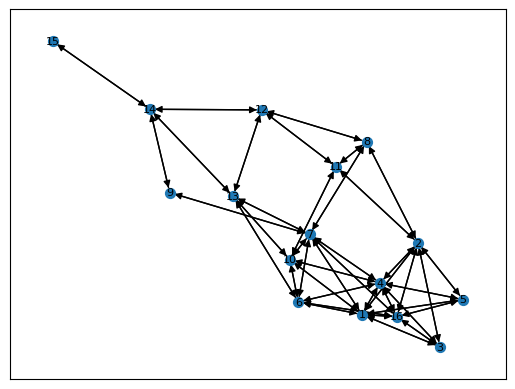

In [241]:
G = nx.from_pandas_edgelist(
    nodes_pairs,  # dataframe containing edges
    source="source_node",  # indicating the start of the edge
    target="target_node",  # indicating the end of the edge
    edge_attr=["time_travel", "energy_consumption"],  # edge costs
    create_using=nx.DiGraph(),  # creating an oriented graph
)

nx.draw_networkx(G, node_size=50, font_size=8)

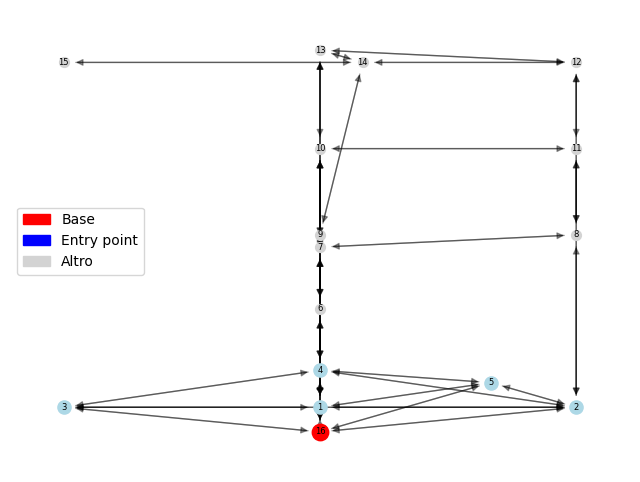

In [242]:
# mappa posizioni (index di `building` sono gli id dei nodi)
pos = {int(idx): (row["x"], row["y"]) for idx, row in building.iterrows()}

# suddividi i nodi per tipo
base_nodes = [int(idx) for idx, row in building.iterrows() if row.get("is_base", False)]
entry_nodes = [int(idx) for idx, row in building.iterrows() if row.get("is_entry_point", False) and not row.get("is_base", False)]
other_nodes = [n for n in G.nodes() if n not in base_nodes + entry_nodes]

plt.figure(figsize=(8,6))
nx.draw_networkx_nodes(G, pos, nodelist=other_nodes, node_size=50, node_color="lightgray")
nx.draw_networkx_nodes(G, pos, nodelist=entry_nodes, node_size=90, node_color="lightblue")
nx.draw_networkx_nodes(G, pos, nodelist=base_nodes, node_size=140, node_color="red")
nx.draw_networkx_edges(G, pos, alpha=0.4)
# opzionale: etichette
nx.draw_networkx_labels(G, pos, font_size=6)

# legenda
import matplotlib.patches as mpatches
legend_handles = [
    mpatches.Patch(color="red", label="Base"),
    mpatches.Patch(color="blue", label="Entry point"),
    mpatches.Patch(color="lightgray", label="Altro")
]
plt.legend(handles=legend_handles)
plt.axis("off")
plt.show()

In [243]:
# For example, accessing edge attributes

energy_consume = G[1][2][
    "energy_consumption"
]  # energy consumption from node 1 to node 2
time = G[1][2]["time_travel"]

print(f"Energy consumption from node 1 to node 2: {energy_consume} J")
print(f"Time travel from node 1 to node 2: {time} s")

Energy consumption from node 1 to node 2: 30.0 J
Time travel from node 1 to node 2: 2.0 s


In [244]:
# iterating over all the list of tuples of edges, data=True to get edge attributes.
for source, target, costs in G.edges(data=True):
    print(f"Arco da {source} a {target}:")
    print(f"    Tempo: {costs['time_travel']}")
    print(f"    Energia: {costs['energy_consumption']}")

Arco da 1 a 2:
    Tempo: 2.0
    Energia: 30.0
Arco da 1 a 3:
    Tempo: 2.0
    Energia: 30.0
Arco da 1 a 4:
    Tempo: 1.0
    Energia: 15.0
Arco da 1 a 5:
    Tempo: 2.0
    Energia: 122.36067977499789
Arco da 1 a 6:
    Tempo: 2.6666666666666665
    Energia: 40.0
Arco da 1 a 7:
    Tempo: 4.333333333333333
    Energia: 65.0
Arco da 1 a 10:
    Tempo: 7.0
    Energia: 105.0
Arco da 1 a 16:
    Tempo: 0.6666666666666666
    Energia: 10.0
Arco da 2 a 1:
    Tempo: 2.0
    Energia: 30.0
Arco da 2 a 3:
    Tempo: 4.0
    Energia: 60.0
Arco da 2 a 4:
    Tempo: 2.23606797749979
    Energia: 33.54101966249685
Arco da 2 a 5:
    Tempo: 2.0
    Energia: 114.14213562373095
Arco da 2 a 8:
    Tempo: 4.666666666666667
    Energia: 70.0
Arco da 2 a 11:
    Tempo: 7.0
    Energia: 105.0
Arco da 2 a 16:
    Tempo: 2.1081851067789197
    Energia: 31.622776601683796
Arco da 3 a 1:
    Tempo: 2.0
    Energia: 30.0
Arco da 3 a 2:
    Tempo: 4.0
    Energia: 60.0
Arco da 3 a 4:
    Tempo: 2.236067977

# MODELLO MIP

In [245]:
# IL DATAFRAME BASES CONTIENE TUTTE LE BASI
# IL DATAFRAME NODES CONTIENE I NODI DEL SET S
# IL NODES_PAIRS CONTIENE GLI ARCHI TRA TUTTI I NODI
# IL SET H È UN INSIEME DI NUMERI DA 0 A UN NUMERO k CHE VA STIMATO BENE

m = mip.Model("DroneTourPlanning")

# SETS AND PARAMETERS
# ---------------------------------------------------------------
N = building.index.tolist()  # All nodes
S = building[building["is_base"] == False].index.tolist()  # Service nodes
B = building[building["is_base"] == True].index.tolist()  # Bases nodes
print(f"set N = {N}")
print(f"set B = {B}")
print(f"set S = {S}")

A = G.edges  # set of arcs
print(f"set A = {A}")

t = {
    (u, v): data["time_travel"] for u, v, data in G.edges(data=True)
}  # dictionary of time travel costs
e = {
    (u, v): data["energy_consumption"] for u, v, data in G.edges(data=True)
}  # dictionary of energy consumption costs
print(f"time travel costs t = {t}")
print(f"energy consumption costs e = {e}")

C = BATTERY_CAPACITY  # battery capacity

set N = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
set B = [16]
set S = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
set A = [(1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 10), (1, 16), (2, 1), (2, 3), (2, 4), (2, 5), (2, 8), (2, 11), (2, 16), (3, 1), (3, 2), (3, 4), (3, 16), (4, 1), (4, 2), (4, 3), (4, 5), (4, 6), (4, 7), (4, 10), (4, 16), (5, 1), (5, 2), (5, 4), (5, 16), (6, 1), (6, 4), (6, 7), (6, 10), (6, 13), (6, 16), (7, 1), (7, 4), (7, 6), (7, 8), (7, 9), (7, 10), (7, 13), (7, 16), (10, 1), (10, 4), (10, 6), (10, 7), (10, 11), (10, 13), (16, 1), (16, 2), (16, 3), (16, 4), (16, 5), (16, 6), (16, 7), (8, 2), (8, 7), (8, 11), (8, 12), (11, 2), (11, 8), (11, 10), (11, 12), (13, 6), (13, 7), (13, 10), (13, 12), (13, 14), (9, 7), (9, 14), (12, 8), (12, 11), (12, 13), (12, 14), (14, 9), (14, 12), (14, 13), (14, 15), (15, 14)]
time travel costs t = {(1, 2): 2.0, (1, 3): 2.0, (1, 4): 1.0, (1, 5): 2.0, (1, 6): 2.6666666666666665, (1, 7): 4.333333333333333, (1, 10

# H E BIG M

In [246]:
# Calculate |H| according to formula: ceil(sum(e_in_min + e_out_min)/C * 1.5)
import math

min_energy_in_out = {}
for i in S:
    incoming = [e[j, i] for j in N if (j, i) in A]
    outgoing = [e[i, j] for j in N if (i, j) in A]
    min_energy_in = min(incoming) if incoming else float("inf")
    min_energy_out = min(outgoing) if outgoing else float("inf")
    min_energy_in_out[i] = min_energy_in + min_energy_out

sum_min_energies = sum(min_energy_in_out.values())
H_length = math.ceil((sum_min_energies / BATTERY_CAPACITY) * 1.5)
H_length= len(S)//2  # As a fallback, use the number of service nodes if the calculated length is too small
H = list(range(1, max(2, H_length + 1)))  # At least 1 tour

print(f"set H = {H}")



# Calculate M according to formula: M = min(|S|, floor(C / min_energy))
positive_energies = [val for val in e.values() if val > 0]
min_energy = min(positive_energies) if positive_energies else 1
print(f"min_energy (positivo) = {min_energy}")
M = min(len(S), int(C / min_energy)) if min_energy > 0 else len(S)
print(f"big M = {M}")

set H = [1, 2, 3, 4, 5, 6, 7]
min_energy (positivo) = 10.0
big M = 15


# VARIABILI

In [247]:
# VARIABLES
# ---------------------------------------------------------------
x = {
    (i, j, h): m.add_var(var_type=mip.BINARY, name=f"x_{i}_{j}_{h}")
    for i, j in A
    for h in H
}  # binary variable indicating if arc (i,j) is used in tour h
b = {
    i: m.add_var(var_type=mip.BINARY, name=f"b_{i}") for i in B
}  # binary variable indicating if base i is used
# u variables only needed for service nodes (bases excluded from MTZ)
u = {
    (i, h): m.add_var(lb=0, ub=M, name=f"u_{i}_{h}") for i in S for h in H
}  # auxiliary variable for subtour elimination

# OBJ FUNCTION


In [248]:

m.objective = mip.minimize(mip.xsum(t[i, j] * x[i, j, h] for i, j in A for h in H))

# CONSTRAINTS

In [249]:

# (1) Only one base is selected
m += mip.xsum(b[i] for i in B) == 1

# (2) Each service node is visited at least once
for i in S:
    m += mip.xsum(x[j, i, h] for j in N for h in H if (j, i) in A) >= 1

# (3) Flow conservation constraints
# Se un tour entra in un nodo, deve anche uscirne (e viceversa).
# Questo vale anche per le basi: se un tour esce dalla base, DEVE rientrarci.
for i in N:
    for h in H:
        m += mip.xsum(x[j, i, h] for j in N if (j, i) in A) == mip.xsum(
            x[i, j, h] for j in N if (i, j) in A
        )

# (4) Trip must depart from a base only if that base is selected
# Se y_b = 0, nessun arco può uscire da b. Per il vincolo (3), nessun arco può entrare.
# Se y_b = 1, al massimo 1 arco uscente per tour h (garantisce tour singolo, non multipli dalla stessa base).
for base in B:
    for h in H:
        m += mip.xsum(x[base, j, h] for j in N if (base, j) in A) <= b[base]

# (5) Energy consumption constraints
for h in H:
    m += mip.xsum(e[i, j] * x[i, j, h] for (i, j) in A) <= C

# (6) Subtour elimination constraints (Miller-Tucker-Zemlin)
# ============================================================================
# PERCHÉ OGNI TOUR DEVE PARTIRE E TORNARE ALLA BASE (dimostrazione implicita):
#
# Caso 1: Tour è un ciclo chiuso tra soli nodi S (es: A → B → C → A)
#         MTZ lo IMPEDISCE! Richiederebbe u_A < u_B < u_C < u_A → impossibile.
#
# Caso 2: Tour è un cammino aperto tra nodi S (es: A → B → C)
#         Vincolo (3) lo IMPEDISCE!
#         - Nodo A avrebbe 0 entranti e 1 uscente → violazione flusso
#         - Nodo C avrebbe 1 entrante e 0 uscenti → violazione flusso
#
# Caso 3: Tour parte dalla base ma non torna (es: Base → A → B → C)
#         Vincolo (3) lo IMPEDISCE!
#         - La Base avrebbe 1 uscente e 0 entranti → violazione flusso
#         - Nodo C avrebbe 1 entrante e 0 uscenti → violazione flusso
#
# Caso 4: Tour torna alla base ma non parte da essa (es: A → B → C → Base)
#         Vincolo (3) lo IMPEDISCE!
#         - Nodo A avrebbe 0 entranti e 1 uscente → violazione flusso
#         - La Base avrebbe 1 entrante e 0 uscenti → violazione flusso
#
# Conclusione: Un tour attivo DEVE essere un ciclo, ma non può essere un ciclo
#              solo tra nodi S. Quindi il ciclo DEVE includere almeno una base.
#              Il vincolo (3) garantisce che il tour parta E torni alla stessa base.
#              Il vincolo (4) garantisce che sia la base selezionata.
# ============================================================================
# NOTA: MTZ non viene applicato agli archi che coinvolgono le basi perché:
# - Arco Base→S: non serve (la base è il "punto zero" implicito)
# - Arco S→Base: se applicassimo u_i - u_base + M*x <= M-1 con u_base=0,
#                otterremmo u_i <= -1 quando x=1, che è INFATTIBILE (u >= 0)
# ============================================================================
for h in H:
    for i, j in A:
        if i in S and j in S:  # Apply MTZ only between service nodes
            m += u[i, h] - u[j, h] + M * x[i, j, h] <= M - 1

# (7) Symmetry Breaking
# Forza l'uso dei tour in ordine (tour 1 ha più archi di tour 2, etc.)
# Riduce lo spazio di ricerca eliminando soluzioni equivalenti permutate.
#for h in range(len(H) - 1):
#    m += mip.xsum(x[i, j, H[h]] for (i, j) in A) >= mip.xsum(
 #       x[i, j, H[h + 1]] for (i, j) in A
  #  )


In [ ]:
import json
from datetime import datetime
import os

# CONFIGURATION FOR OPTIMIZATION
#---------------------------------------------------------------
TEST_NAME = "test_optimization"
OPTIMIZATION_TIMEOUT = 10  # 2 hours in seconds (fixed from 200)
LOG_DIR = "optimization_logs"
RESULTS_DIR = "optimization_results"

# Create directories if they don't exist
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

def create_solution_summary(model, duration_seconds, timeout_seconds):
    """Extract and format solution information"""
    summary = {
        "timestamp": datetime.now().isoformat(),
        "duration_seconds": duration_seconds,
        "timeout_seconds": timeout_seconds,
        "solution_found": model.num_solutions > 0,
        "num_solutions_found": model.num_solutions,
        "status": str(model.status),
    }
    
    # Always save best bound (lower bound on optimal value)
    summary["best_bound"] = float(model.objective_bound) if (hasattr(model, 'objective_bound') and model.objective_bound is not None) else None
    
    # Solution-specific information
    if model.num_solutions > 0:
        summary["optimal_value"] = float(model.objective_value)
        summary["gap"] = float(model.gap) if (hasattr(model, 'gap') and model.gap is not None) else None
        
        # Try to extract the selected base
        try:
            summary["selected_base"] = [int(i) for i in B if model.get_var_by_name(f"b_{i}").x >= 0.99][0]
        except Exception:
            summary["selected_base"] = "N/A"
        
        # Extract tours for each h
        tours = {}
        for h in H:
            tour_arcs = [(i, j) for i, j in A if model.get_var_by_name(f"x_{i}_{j}_{h}").x >= 0.99]
            if tour_arcs:
                tours[f"tour_{h}"] = tour_arcs
        summary["tours"] = tours
    else:
        summary["optimal_value"] = None
        summary["gap"] = None
        summary["best_bound_only"] = summary["best_bound"]
    
    return summary

def save_results(summary, test_name=TEST_NAME):
    """Save results to both JSON and text files with robust encoding"""
    timestamp = datetime.now().strftime("%d%m%Y_%H%M%S")
    
    # Save JSON
    json_path = os.path.join(RESULTS_DIR, f"{test_name}.json")
    with open(json_path, 'w', encoding='utf-8', errors='replace') as f:
        json.dump(summary, f, indent=2, ensure_ascii=False)
    
    # Save human-readable text
    txt_path = os.path.join(RESULTS_DIR, f"{test_name}.txt")
    with open(txt_path, 'w', encoding='utf-8', errors='replace') as f:
        f.write("="*70 + "\n")
        f.write(f"OPTIMIZATION RESULTS - {timestamp}\n")
        f.write("="*70 + "\n\n")
        f.write(f"Duration: {summary['duration_seconds']:.2f} seconds ({summary['duration_seconds']/60:.2f} minutes)\n")
        f.write(f"Timeout: {summary['timeout_seconds']} seconds ({summary['timeout_seconds']/3600:.1f} hours)\n")
        f.write(f"Status: {summary['status']}\n")
        f.write(f"Solution Found: {summary['solution_found']}\n")
        f.write(f"Number of solutions found: {summary['num_solutions_found']}\n\n")
        
        if summary['solution_found']:
            f.write("[OK] FEASIBLE SOLUTION FOUND\n")
            f.write("-" * 70 + "\n")
            f.write(f"Optimal Objective Value: {summary['optimal_value']:.2f} seconds\n")
            f.write(f"Best Bound (Lower Bound): {summary['best_bound']:.2f}\n")
            if summary['gap'] is not None:
                f.write(f"Optimality Gap: {summary['gap']*100:.2f}%\n")
                f.write(f"  (Gap < 1% means solution is very close to optimal)\n")
            f.write(f"\nSelected Base: Node {summary['selected_base']}\n")
            f.write(f"Number of Tours: {len(summary.get('tours', {}))}\n\n")
            f.write("Tours details:\n")
            for tour_name, arcs in summary.get('tours', {}).items():
                f.write(f"  {tour_name}: {len(arcs)} arcs\n")
                f.write(f"    Path: {arcs}\n")
        else:
            f.write("[X] NO FEASIBLE SOLUTION FOUND\n")
            f.write("-" * 70 + "\n")
            f.write(f"The solver could not find any feasible solution within {summary['timeout_seconds']} seconds.\n")
            if summary['best_bound'] is not None:
                f.write(f"\nPartial Information:\n")
                f.write(f"  Best Lower Bound found: {summary['best_bound']:.2f}\n")
                f.write(f"  This means: any feasible solution MUST have cost >= {summary['best_bound']:.2f}\n")
            f.write(f"\nPossible reasons:\n")
            f.write(f"  - Problem may be infeasible (no solution exists)\n")
            f.write(f"  - Timeout was not enough to find a solution\n")
            f.write(f"  - Model constraints may be too restrictive\n")
        
        f.write("\n" + "="*70 + "\n")
    
    print(f"Results saved to: {json_path}")
    print(f"Summary saved to: {txt_path}")
    
    return json_path, txt_path

# RUN OPTIMIZATION
#---------------------------------------------------------------
print("Starting optimization...")
print(f"Timeout: {OPTIMIZATION_TIMEOUT} seconds ({OPTIMIZATION_TIMEOUT/3600:.1f} hours)\n")

start_time = datetime.now()
m.optimize(max_seconds=OPTIMIZATION_TIMEOUT)
end_time = datetime.now()

# Process and save results
summary = create_solution_summary(m, (end_time - start_time).total_seconds(), OPTIMIZATION_TIMEOUT)
json_file, txt_file = save_results(summary, test_name=TEST_NAME)

# Display summary in console (using safe characters)
print("\n" + "="*70)
print("OPTIMIZATION SUMMARY")
print("="*70)
print(f"Duration: {summary['duration_seconds']:.2f} seconds ({summary['duration_seconds']/60:.2f} minutes)")
print(f"Status: {summary['status']}")
print(f"Solutions found: {summary['num_solutions_found']}")

if summary['solution_found']:
    print(f"\n[OK] FEASIBLE SOLUTION FOUND")
    print(f"  Optimal Value: {summary['optimal_value']:.2f} seconds")
    if summary['best_bound'] is not None:
        print(f"  Best Lower Bound: {summary['best_bound']:.2f}")
    if summary['gap'] is not None:
        print(f"  Optimality Gap: {summary['gap']*100:.2f}%")
    print(f"  Selected Base: Node {summary.get('selected_base')}")
    print(f"  Number of Tours: {len(summary.get('tours', {}))}")
else:
    print(f"\n[X] NO FEASIBLE SOLUTION FOUND")
    if summary['best_bound'] is not None:
        print(f"  Best Lower Bound: {summary['best_bound']:.2f}")
        print(f"  (Any feasible solution must have cost >= this value)")

print("\n" + "="*70)

Starting optimization...
Timeout: 10 seconds (0.0 hours)



TypeError: float() argument must be a string or a real number, not 'NoneType'